# Dynesty results — visualization

`run_dynesty.py` writes one pickle per insolation model; `load_fits` reads them back as the `{model: NestedFit}` dict every plotting helper takes. Each fit carries **its own data, priors, injected truth and `FittingConfig`**, so nothing has to be re-typed here — `logl_from_fit` rebuilds the exact likelihood the sampler used (needed by 1., 3. and 5., which still evaluate the forward model). It also checks that the forward model has not changed since the run (`check_fit_current`: the stellar grid pickled with the fit against the one the current code builds), since a fit sampled with another stellar SED, filter convention or band is not a posterior of today's likelihood.

The models need not share a parameter set: `hyperillum` and `naive` sample $(A_B, \mathrm{offset})$, `naive_redist` additionally the heat redistribution $F$ (Kreidberg & Loeb 2016, eq. 1). Everything $F$-specific — its slice, the $(A_B, F)$ map and posterior, the corner plot, the joint noiseless fit with the false-positive $F$ and the nightside temperature it implies — appears automatically when a `naive_redist` run is part of the dataset.

A dataset may also be a **joint fit of several detectors** (`run_dynesty.py` with `"JWST_NIRSpec.G395H_joint"` or a tuple of bands): one shared $(A_B, F)$, one baseline `offset_<label>` per detector, the detectors' data drawn from one noise stream. The loader detects it from the saved `FittingConfig` tuple; the slices, maps and posterior overlays then come per baseline, and the data, posterior-predictive, bias and depth figures per detector.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dynesty_utils import *
from paper_plot_utils import paper_figure, paper_theme
from dynesty import utils as dyfunc, plotting as dyplot
from dataclasses import replace
import glob, os

N_JOBS = -1      # forward models run process-parallel (loky); the plots below are the only likelihood cost
INSOL_REF = "hyperillum"   # the model the data were drawn from: always fitted, so it is the reference for the shared (A_B, offset) box and the denominator-free side of every Bayes factor
COLOR  = {"naive": "C0", "hyperillum": "C3", "naive_redist": "C2"}

In [2]:
# --- load data file ---------------------------------------------------------------------------------------
# the DATASET tag: one pattern matching EVERY model of one run, whatever each was sampled with
# (the file names end in _{insolation_model}_priors-..., so this prefix does not fix the free parameters)
RESULTS_DIR = "dynesty_results"   # where run_dynesty.py saves

# run_dynesty.py with the baseline settings (DEFAULT_A_B, DEFAULT_N_ORBITS, ... of HItargets_utils; PandExo noise from the cache), 2026-11-08:
# the joint NRS1 + NRS2 fit (instruments entry "JWST_NIRSpec.G395H_joint"; one baseline per detector, the two noise levels joined by "+" in the tag) and the single NRS1 band
results_file = "TOI-2431b_JWST_NIRSpec.G395H_joint_fixedA0.1_AB0.2_nbins27_norbits5_rms1min39.1+49.4_sigmascale1_seed42"
# results_file = "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.2_nbins27_norbits5_rms1min39.1_sigmascale1_seed42"

# Older datasets in "more runs/" (2026-10: blackbody star, old filter convention, A_B = 0.42, 3 orbits, old PandExo binning). They were sampled with a different forward
# model, so logl_from_fit refuses them (older FittingConfig) or warns (check_fit_current): re-run them with run_dynesty.py before analysing them here.
OLD_RESULTS = [
    # K2 141b
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale1_seed42",
    "K2-141b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min51.7_sigmascale1_seed42",
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.1_nbins27_norbits3_rms1min154.5_sigmascale1_seed42",
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale0.1_seed42",
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale0.5_seed42",
    "K2-141b_MIRI-LRS_scaledA1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale1_seed42",
    # TOI 2431b
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed43",
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed42",
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed41",
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed40",
    "TOI-2431b_MIRI-F1280W_fixedA0.1_AB0.42_nbins27_norbits3_rms1min247.2_sigmascale1_seed42",
    "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min91.9_sigmascale0.1_seed42",
    "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min91.9_sigmascale0.5_seed42",
    "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min91.9_sigmascale1_seed42",
    # K2-157b
    "K2-157b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min1102.9_sigmascale1_seed42",
    # KOI-1843.03
    "KOI-1843.03_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min868.8_sigmascale1_seed42",
    # TOI-2260b
    "TOI-2260b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min182.0_sigmascale1_seed42",
]
# RESULTS_DIR, results_file = "more runs/OLD_before_midpoint_binning/dynesty_results", OLD_RESULTS[7]

RESULTS = f"{RESULTS_DIR}/{results_file}_*.pkl"


In [3]:
fits  = load_fits(RESULTS)                                    # {insolation_model: NestedFit}; whichever models the pattern found
fits  = {m: fits[m] for m in ("hyperillum", "naive", "naive_redist") if m in fits}   # fixed order, so colours and panels do not depend on how the files happened to sort
logls = {m: logl_from_fit(f) for m, f in fits.items()}        # the likelihood each fit was run with, rebuilt from its own cfg (a JointGaussianLogL for a joint detector fit)

# The models need NOT share a ParameterSet: only "naive_redist" samples F. Everything shared comes from the truth's own model, which is always run.
ref   = fits[INSOL_REF]
pset  = ref.pset                                               # the (A_B, baselines) box every model has - what the grids below are built on
PSETS = {m: f.pset for m, f in fits.items()}                   # what each model was ACTUALLY sampled with
cfg   = ref.meta["cfg"]                                        # one FittingConfig, or the detector set (tuple) of a joint fit
cfgs  = detector_cfgs(cfg); cfg0 = cfgs[0]                     # cfg0 carries everything band-independent (planet, binning)
LABELS = list(ref.meta.get("labels") or [])                    # detector labels of a joint fit ("NRS1", "NRS2"), [] for a single band
JOINT  = len(cfgs) > 1
data  = ref.meta["data"]                                       # per-detector dicts under data["detectors"] for a joint fit
truth = data["truth"]                                          # what simulate_data injected
A_B_true, INSOL_TRUTH = truth["A_B"], truth["insolation_model"]
assert INSOL_TRUTH == INSOL_REF, f"the data were drawn from {INSOL_TRUTH}, but INSOL_REF is {INSOL_REF}"
OFFSET_NAMES = [n for n in pset.names if n.startswith("offset")]   # "offset", or one "offset_<label>" per detector
# the injected value of every parameter ANY model samples. Only a "naive_redist" truth has an F; otherwise the data are drawn without redistribution and F = 0 is the truth for it too.
TRUTH_OF = dict(A_B=A_B_true, F=truth.get("F") if truth.get("F") is not None else 0., **{o: truth["offset"] for o in OFFSET_NAMES})
base  = {n: TRUTH_OF[n] for f in fits.values() for n in f.pset.names}

print(f"{cfg0.planet.name}   truth = {INSOL_TRUTH}, A_B = {A_B_true:g}" + (f", F = {truth['F']:g}" if truth.get("F") is not None else "") + f", offset = {truth['offset']:g} ppm, data seed = {truth['seed']}" + ("   |   JOINT fit of " + " + ".join(LABELS) if JOINT else ""))
for c, lab in zip(cfgs, LABELS or [""]):
    print(f"   {lab:5s} [{c.l1*1e6:.2f}-{c.l2*1e6:.2f} um]  rms_1min = {c.sigma_1min:.1f} ppm -> sigma_bin = {c.sigma_bin:.1f} ppm over {c.n_bins} bins x {c.n_orbits} orbits")
print(f"models: {', '.join(fits)}\n")
print(f"{'model':12s} {'lnZ':>20s} {'ncall':>8s} {'runtime':>9s}   status   (ESS is part of the status line)")
for m, f in fits.items():
    print(f"{m:12s} {f.meta['lnZ']:10.4f} +/- {f.meta['lnZ_err']:.4f} {f.meta['ncall']:8d} {f.meta['runtime_s']/60:7.1f} m   {f.meta['status']}")
    print(f"{'':12s} sampled: {', '.join(f.pset.names)}")
    print(f"{'':12s} {os.path.basename(f.meta.get('file', '(not saved)'))}")

TOI-2431 b   truth = hyperillum, A_B = 0.2, offset = 0 ppm, data seed = 42   |   JOINT fit of NRS1 + NRS2
   NRS1  [2.90-3.70 um]  rms_1min = 39.1 ppm -> sigma_bin = 5.1 ppm over 27 bins x 5 orbits
   NRS2  [3.80-5.20 um]  rms_1min = 49.4 ppm -> sigma_bin = 6.4 ppm over 27 bins x 5 orbits
models: hyperillum, naive, naive_redist

model                         lnZ    ncall   runtime   status   (ESS is part of the status line)
hyperillum    -168.9659 +/- 0.0782    38697    10.0 m   CONVERGED | stop 0.973, 8/10 batches, ESS 9797
             sampled: A_B, offset_NRS1, offset_NRS2
             TOI-2431b_JWST_NIRSpec.G395H_joint_fixedA0.1_AB0.2_nbins27_norbits5_rms1min39.1+49.4_sigmascale1_seed42_hyperillum_priors-A_B+offset_NRS1+offset_NRS2.pkl
naive         -173.2122 +/- 0.0778    38051    16.5 m   CONVERGED | stop 0.983, 8/10 batches, ESS 9668
             sampled: A_B, offset_NRS1, offset_NRS2
             TOI-2431b_JWST_NIRSpec.G395H_joint_fixedA0.1_AB0.2_nbins27_norbits5_rms1min39.1+49

## 1. Data and Likelihood

Plotted as $\Delta\ln\mathcal{L}=\ln\mathcal{L}-\ln\mathcal{L}_{\max}$. In the slices the dotted lines at $-0.5,-2,-4.5$ are the 1-parameter $1/2/3\sigma$ levels; in the maps the contours are the 2-parameter ones ($-1.15,-3.09,-5.91$). With uniform priors $\exp(\ln\mathcal{L})$ over the box *is* the un-normalised posterior, so the maps preview the corner plots in 2.

The slices hold every other parameter at the injected truth, so in the $A_B$ and offset panels `naive_redist` (at its injected $F=0$) **is** the naive model and its dashed curve lies on top of the naive one. The $F$ slice and the $(A_B, F)$ map appear only when a `naive_redist` run is loaded; in that map the additive offset is profiled out (maximised per cell, free since it reuses the cell's forward model), because it correlates with $F$ and a fixed-offset slice would look tighter than the fit is. The $F$ axes are zoomed to where the likelihood is still on the panel, on a linear scale.

For a joint fit there is one baseline per detector: a slice and an $(A_B, \mathrm{offset})$ map per baseline (the other detectors' baselines at the truth), and in the $(A_B, F)$ map every baseline is profiled out. The data figure shows one column per detector.


NRS1: sigma_bin: 5.06 ppm  (bin width 11.96 min)
NRS1: chi2 / n_bins (normalized average noise per bin ~1): 0.63
NRS1: residual mean / sigma (~0): -0.03


NRS2: sigma_bin: 6.39 ppm  (bin width 11.96 min)
NRS2: chi2 / n_bins (normalized average noise per bin ~1): 0.56
NRS2: residual mean / sigma (~0): 0.16


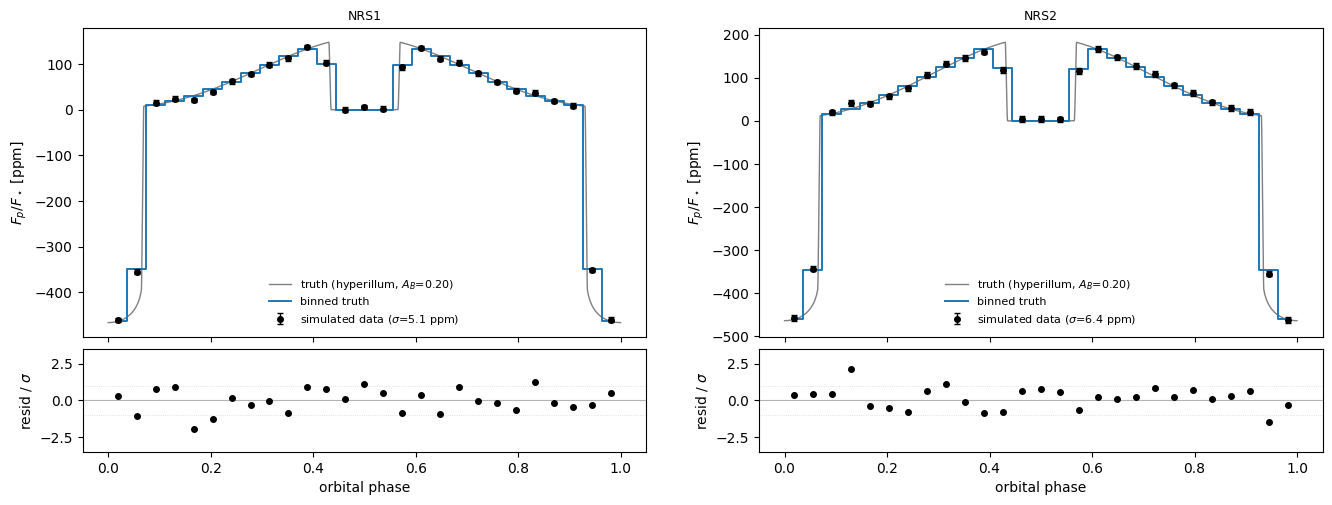

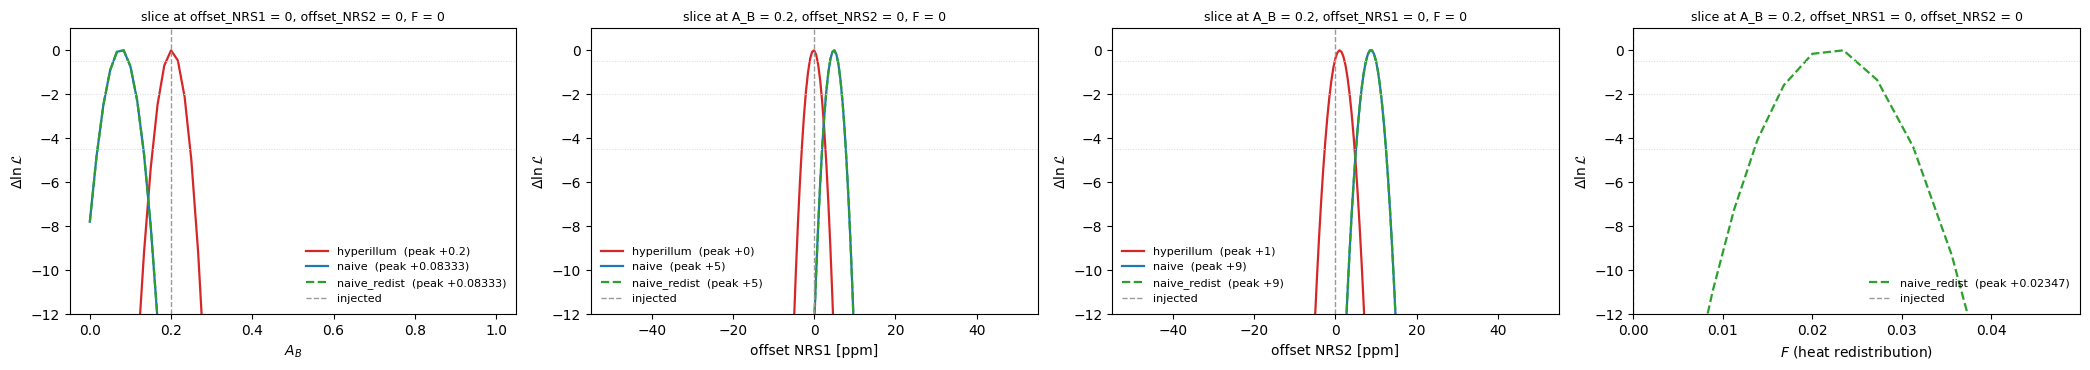

hyperillum   grid MAP: A_B = 0.2000, offset_NRS1 = +0.00 ppm, lnL = -159.527


naive        grid MAP: A_B = 0.1000, offset_NRS1 = +2.00 ppm, lnL = -177.179


naive_redist grid MAP: A_B = 0.1000, offset_NRS1 = +2.00 ppm, lnL = -177.174


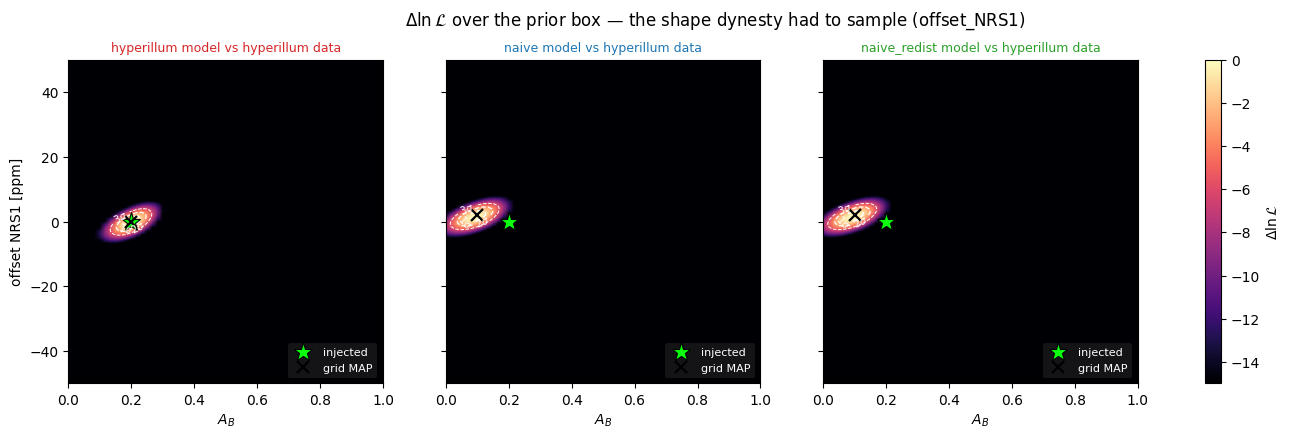

hyperillum   grid MAP: A_B = 0.2167, offset_NRS2 = +1.50 ppm, lnL = -159.008


naive        grid MAP: A_B = 0.1167, offset_NRS2 = +6.00 ppm, lnL = -168.594


naive_redist grid MAP: A_B = 0.1167, offset_NRS2 = +6.00 ppm, lnL = -168.593


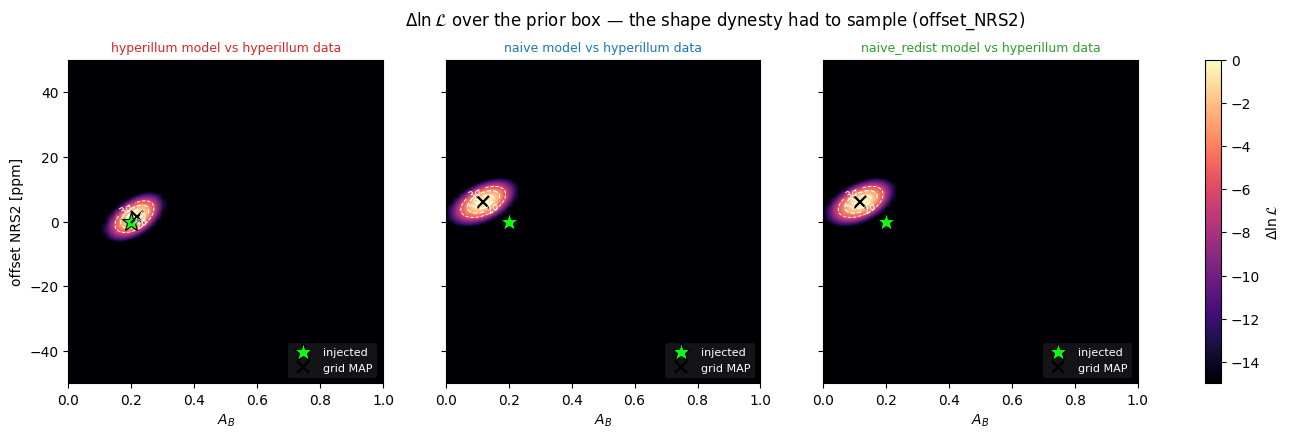

naive_redist grid MAP: A_B = 0.1500, F = 0.0100, lnL = -161.564   (offset profiled out)


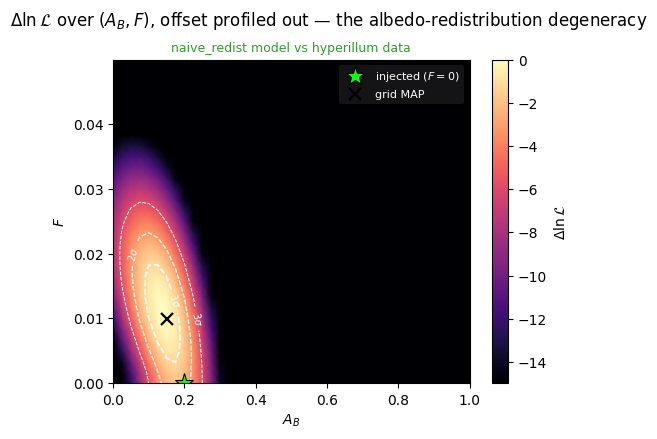

In [4]:
PAPER_MODE = False
A_grid, O_grid = pset.grid("A_B", 61),  pset.grid(OFFSET_NAMES[0], 201)   # every baseline has the same prior OFFSET_BOUNDS
PLANET = cfg0.planet.name.replace(' ', '')

# the truth curve is re-evaluated here (one forward model per detector), the data points come straight out of the saved fit
plot_simulated_data(cfg, A_B_true, data, insolation_model=INSOL_TRUTH, labels=LABELS or None)
paper_figure(f"dynesty_simulated_data_{PLANET}", PAPER_MODE, tight=False)
plt.show()

# 1D slices. One panel per parameter ANY model samples - so F gets its own as soon as a "naive_redist" run is loaded,
# and the models that do not sample it simply have no curve there; a joint fit has one baseline panel per detector.
F_MODELS = [m for m in fits if "F" in PSETS[m].names]          # [] when no redistribution run is in this dataset
GRIDS  = {"A_B": A_grid, **{o: O_grid for o in OFFSET_NAMES}}
if F_MODELS:   # F nodes over the full prior but quadratically dense towards 0, where the likelihood sits (the response to F is ~F^1.5 near 0 and the posterior is a sliver of the prior); the panel is zoomed below
    lo_F, hi_F = PSETS[F_MODELS[0]].bounds[PSETS[F_MODELS[0]].names.index("F")]
    GRIDS["F"] = lo_F + (hi_F - lo_F) * np.linspace(0., 1., 61) ** 2
XLABEL = {"A_B": "$A_B$", "F": "$F$ (heat redistribution)", **{o: o.replace("offset_", "offset ") + " [ppm]" for o in OFFSET_NAMES}}
YLIM   = -12.

SLICES = {}
fig, axes = plt.subplots(1, len(GRIDS), figsize=(5.25 * len(GRIDS), 3.8), squeeze=False)
for ax, (p, g) in zip(axes.ravel(), GRIDS.items()):
    for name, L in logls.items():
        if p not in L.names: continue                          # e.g. F, which only "naive_redist" has
        s = logl_slice(L, p, g, base, n_jobs=N_JOBS)           # one forward model per node, except the baselines (additive -> free)
        SLICES[p, name] = s
        # dashed for naive_redist: at the injected F = 0 it IS the naive model, so in the A_B and offset panels the two curves lie exactly on top of each other
        ax.plot(g, s - s.max(), color=COLOR[name], lw=1.6, ls="--" if name == "naive_redist" else "-", label=f"{name}  (peak {g[s.argmax()]:+.4g})")
    for d in (-0.5, -2.0, -4.5):
        ax.axhline(d, color="0.85", lw=0.7, ls=":")
    ax.axvline(base[p], color="0.6", lw=1.0, ls="--", label="injected")
    ax.set_xlabel(XLABEL[p]); ax.set_ylabel(r"$\Delta\ln\mathcal{L}$")
    ax.set_ylim(YLIM, 1.); ax.legend(frameon=False, fontsize=8)
    ax.set_title("slice at " + ", ".join(f"{q} = {base[q]:g}" for q in GRIDS if q != p), fontsize=9)
    if p == "F":   # the F posterior is a sliver against its [0, 0.5] prior, so zoom the axis to where the curve is still on the panel (linear, never sqrt)
        on = np.concatenate([g[(SLICES[p, m] - SLICES[p, m].max()) > YLIM] for m in F_MODELS])
        F_LIM = (g[0], min(g[-1], on.max() + 0.5 * np.ptp(on) + 1e-3))   # from the prior floor F = 0 (the injected truth and the physical edge) up to where the curve leaves the panel; reused by the (A_B, F) map below
        ax.set_xlim(*F_LIM)
plt.tight_layout(); paper_figure(f"dynesty_lnL_slices_{PLANET}", PAPER_MODE); plt.show()

# 2D maps over (A_B, baseline), one figure per baseline (a joint fit has one per detector; the other baselines stay at the truth)
lnL_maps = {}   # {baseline: {model: (lnL, lnLmax, A_map, off_map)}}
for o in OFFSET_NAMES:
    lnL_maps[o] = {}
    for name, L in logls.items():
        lnL = logl_grid(L, "A_B", A_grid, o, O_grid, base, n_jobs=N_JOBS)       # (n_off, n_A_B)
        lnLmax, (off_map, A_map) = grid_max(lnL, O_grid, A_grid)                   # axis order of lnL: (offset, A_B)
        lnL_maps[o][name] = (lnL, lnLmax, A_map, off_map)
        print(f"{name:12s} grid MAP: A_B = {A_map:.4f}, {o} = {off_map:+.2f} ppm, lnL = {lnLmax:.3f}")

    fig, axes = plt.subplots(1, len(logls), figsize=(5.75 * len(logls), 4.2), sharex=True, sharey=True, squeeze=False)
    axes = axes.ravel()
    for ax, (name, (lnL, lnLmax, A_map, off_map)) in zip(axes, lnL_maps[o].items()):
        d = lnL - lnLmax
        im = ax.pcolormesh(A_grid, O_grid, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
        cs = ax.contour(A_grid, O_grid, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
        ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
        ax.plot(A_B_true, base[o], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected")   # not C0/C3: those now mean naive/hyperillum
        ax.plot(A_map, off_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")   # the MAP always sits in the bright peak
        ax.set_xlabel("$A_B$")
        ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
        ax.legend(loc="lower right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    axes[0].set_ylabel(XLABEL[o])
    fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")   # shared: all panels use vmin=-15, vmax=0
    fig.suptitle(r"$\Delta\ln\mathcal{L}$ over the prior box — the shape dynesty had to sample" + (f" ({o})" if JOINT else ""), y=1.0)
    paper_figure(f"dynesty_lnL_maps_{PLANET}" + (f"_{o}" if JOINT else ""), PAPER_MODE)
    plt.show()

# 2D map over (A_B, F), the pair the whole naive_redist fit is about: how much albedo the fit trades for how much
# redistribution. The additive baseline(s) are PROFILED OUT rather than held at base (they correlate with F, so a fixed-offset
# slice looks tighter than the fit is) - free, since every offset reuses the cell's one forward model (per detector for a joint fit).
lnL_maps_F = {}
if F_MODELS:
    A_gridF = pset.grid("A_B", 41)
    F_gridF = np.linspace(*F_LIM, 31)   # the same zoom as the slice panel, so the two F figures are on one scale
    for name in F_MODELS:
        lnL = logl_grid(logls[name], "A_B", A_gridF, "F", F_gridF, base, n_jobs=N_JOBS, profile_offset=O_grid)   # (n_F, n_A_B)
        lnLmax, (F_map, A_map) = grid_max(lnL, F_gridF, A_gridF)                                                 # axis order of lnL: (F, A_B)
        lnL_maps_F[name] = (lnL, lnLmax, A_map, F_map)
        print(f"{name:12s} grid MAP: A_B = {A_map:.4f}, F = {F_map:.4f}, lnL = {lnLmax:.3f}   (offset profiled out)")

    fig, axes = plt.subplots(1, len(lnL_maps_F), figsize=(5.75 * len(lnL_maps_F), 4.2), sharex=True, sharey=True, squeeze=False)
    for ax, (name, (lnL, lnLmax, A_map, F_map)) in zip(axes.ravel(), lnL_maps_F.items()):
        d = lnL - lnLmax
        im = ax.pcolormesh(A_gridF, F_gridF, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
        cs = ax.contour(A_gridF, F_gridF, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
        ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
        ax.plot(A_B_true, base["F"], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected ($F=0$)")
        ax.plot(A_map, F_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")
        ax.set_xlabel("$A_B$")
        ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
        ax.legend(loc="upper right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    axes.ravel()[0].set_ylabel("$F$")
    fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")
    fig.suptitle(r"$\Delta\ln\mathcal{L}$ over $(A_B, F)$, offset profiled out — the albedo-redistribution degeneracy", y=1.0)
    paper_figure(f"dynesty_lnL_maps_AB_F_{PLANET}", PAPER_MODE)
    plt.show()

## 2. Dynesty results

Posterior overlay (filled: the sampler's 68/95% credible regions from `samples_equal()`; dotted: the profile-likelihood contours from 1.), the per-parameter bias against the injected truth, and one Bayes factor per alternative model, each against the truth's own model. With a `naive_redist` run: the $(A_B, F)$ posterior against the profile-likelihood map of 1., the full corner plot, and the upper limits on $F$ — its posterior is one-sided against the $F \geq 0$ prior, so a median $\pm$ interval misdescribes it. The one-seed fits against the noiseless truth are in 4.


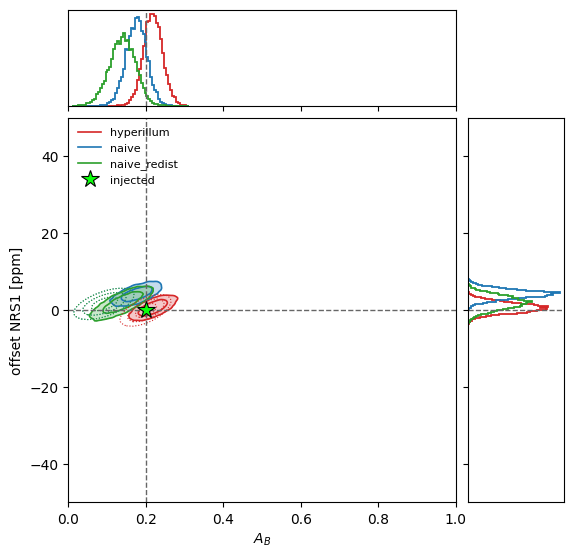

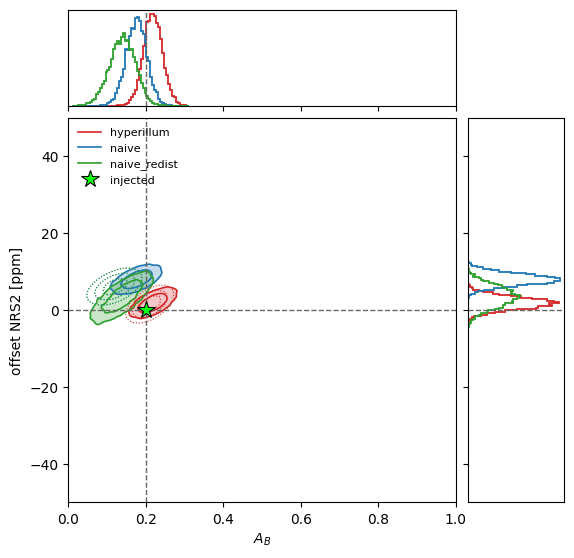

hyperillum   ESS 9797, information 8.59 nats
   A_B      =    0.2183 +0.0241 -0.0247   truth 0.2, bias +0.0183 = +0.75 sigma
   offset_NRS1 =    0.5535 +1.3708 -1.3423   truth 0, bias +0.5535 = +0.41 sigma
   offset_NRS2 =    1.8218 +1.5911 -1.5795   truth 0, bias +1.8218 = +1.15 sigma
   corr(A_B, offset_NRS1) = +0.684
   corr(A_B, offset_NRS2) = +0.632
   corr(offset_NRS1, offset_NRS2) = +0.429
naive   ESS 9668, information 8.40 nats
   A_B      =    0.1766 +0.0258 -0.0266   truth 0.2, bias -0.0234 = -0.89 sigma
   offset_NRS1 =    4.1587 +1.2335 -1.2550   truth 0, bias +4.1587 = +3.34 sigma
   offset_NRS2 =    7.9379 +1.5292 -1.4873   truth 0, bias +7.9379 = +5.26 sigma
   corr(A_B, offset_NRS1) = +0.652
   corr(A_B, offset_NRS2) = +0.587
   corr(offset_NRS1, offset_NRS2) = +0.378
naive_redist   ESS 10426, information 11.57 nats
   A_B      =    0.1401 +0.0322 -0.0344   truth 0.2, bias -0.0599 = -1.80 sigma
   offset_NRS1 =    1.9431 +1.7678 -1.8447   truth 0, bias +1.9431 = +1.08 s

ln B (hyperillum vs naive) = +4.246 +/- 0.110 (analytic) +/- 0.183 (jitter, K=200)  ->  B = 69.8
P(sign of ln B secure) = 1.000  [sampler noise only, NOT a model probability]


ln B (hyperillum vs naive_redist) = +6.061 +/- 0.122 (analytic) +/- 0.176 (jitter, K=200)  ->  B = 429
P(sign of ln B secure) = 1.000  [sampler noise only, NOT a model probability]


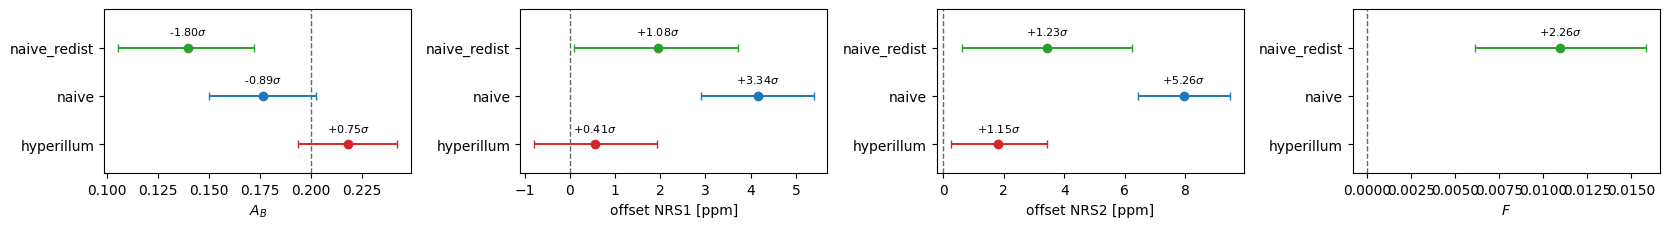

naive_redist: F < 0.0133 (68 %), F < 0.0192 (95 %)   [injected F = 0]


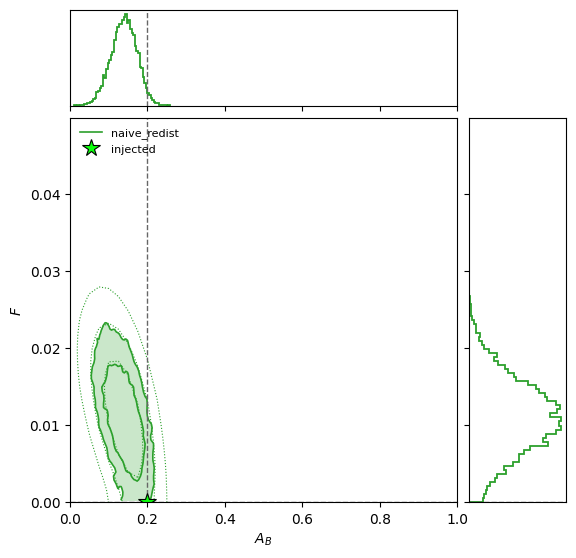

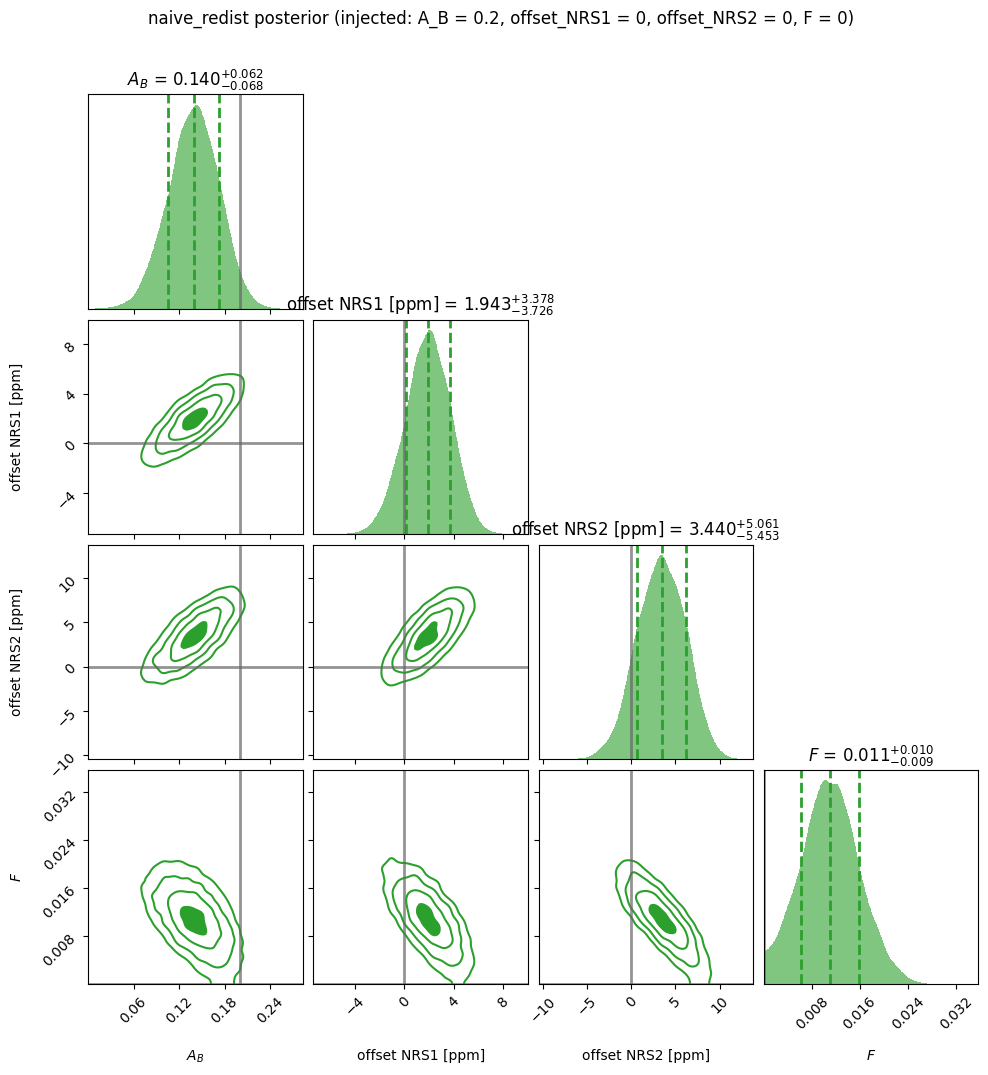

In [5]:
PAPER_MODE = False
# Posterior, one (A_B, baseline) plane per baseline
for o in OFFSET_NAMES:
    profile = {name: (A_grid, O_grid, lnL) for name, (lnL, *_) in lnL_maps[o].items()}   # logl_grid returns (offset, A_B), which is what contour(A_grid, O_grid, ...) wants
    plot_posterior_overlay(fits, "A_B", o, truth=base, profile=profile, colors=COLOR)
    paper_figure(f"dynesty_posterior_AB_{o}_{PLANET}", PAPER_MODE, tight=False)
    plt.show()

# Bayes Factor lnB
for f in fits.values(): posterior_summary(f, base)
# one Bayes factor per alternative present, each against the truth's own model
bfs = {m: bayes_factor(fits, INSOL_REF, m, K=200) for m in fits if m != INSOL_REF}

plot_bias(fits, base, colors=COLOR); paper_figure(f"dynesty_bias_{PLANET}", PAPER_MODE); plt.show()

# F-specific posteriors, whenever a loaded model samples it
for m in F_MODELS:   # one-sided against the F >= 0 prior: quote upper limits, not median +/- interval
    w, iF = fits[m].results.importance_weights(), PSETS[m].names.index("F")
    q68, q95 = dyfunc.quantile(fits[m].results.samples[:, iF], [0.68, 0.95], weights=w)
    print(f"{m}: F < {q68:.4f} (68 %), F < {q95:.4f} (95 %)   [injected F = {base['F']:g}]")
if F_MODELS:
    # the (A_B, F) plane: filled = the sampler's credible regions, dotted = the profile-likelihood contours of the map in 1.
    plot_posterior_overlay({m: fits[m] for m in F_MODELS}, "A_B", "F", truth=base,
                           profile={m: (A_gridF, F_gridF, lnL) for m, (lnL, *_) in lnL_maps_F.items()}, colors=COLOR)
    paper_figure(f"dynesty_posterior_AB_F_{PLANET}", PAPER_MODE, tight=False)
    plt.show()

    # full corner: F against every other sampled parameter, from the equal-weight posterior
    for m in F_MODELS:
        fig, _ = dyplot.cornerplot(fits[m].results, labels=list(PSETS[m].labels), color=COLOR[m],
                                   truths=[base[n] for n in PSETS[m].names], truth_color="0.4",
                                   show_titles=True, title_fmt=".3f", quantiles=(0.16, 0.5, 0.84),
                                   fig=plt.subplots(PSETS[m].ndim, PSETS[m].ndim, figsize=(2.6 * PSETS[m].ndim,) * 2))
        fig.suptitle(f"{m} posterior (injected: " + ", ".join(f"{n} = {base[n]:g}" for n in PSETS[m].names) + ")", y=1.04)
        paper_figure(f"dynesty_corner_{m}_{PLANET}", PAPER_MODE, tight=False)
        plt.show()

## 3. Posterior predictive — and where in phase the evidence comes from

Bottom panel (the `num` - `den` pair only; every model is still in the two panels above): the difference of the two median curves against $\pm\sigma_{\rm bin}$, plus the per-bin $\Delta\chi^2$ between the two **best-fit** (max-$\ln\mathcal{L}$) models. Those bars sum to $2\,\Delta\ln\mathcal{L}_{\max}$, so they attribute the evidence to specific orbital phases. One figure per alternative model, each against the truth's own model (the same pairs as the Bayes factors in 2.).

Costs `N_DRAWS` forward models per insolation model and figure.


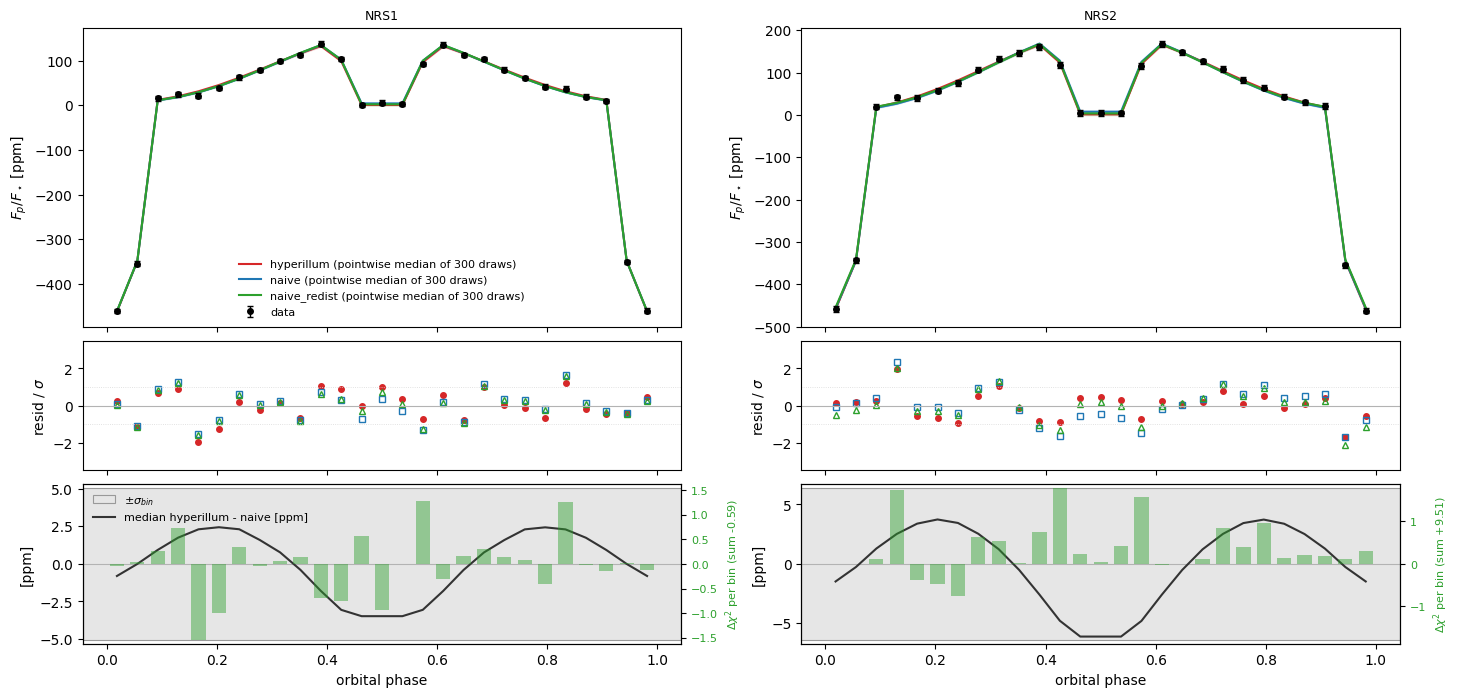

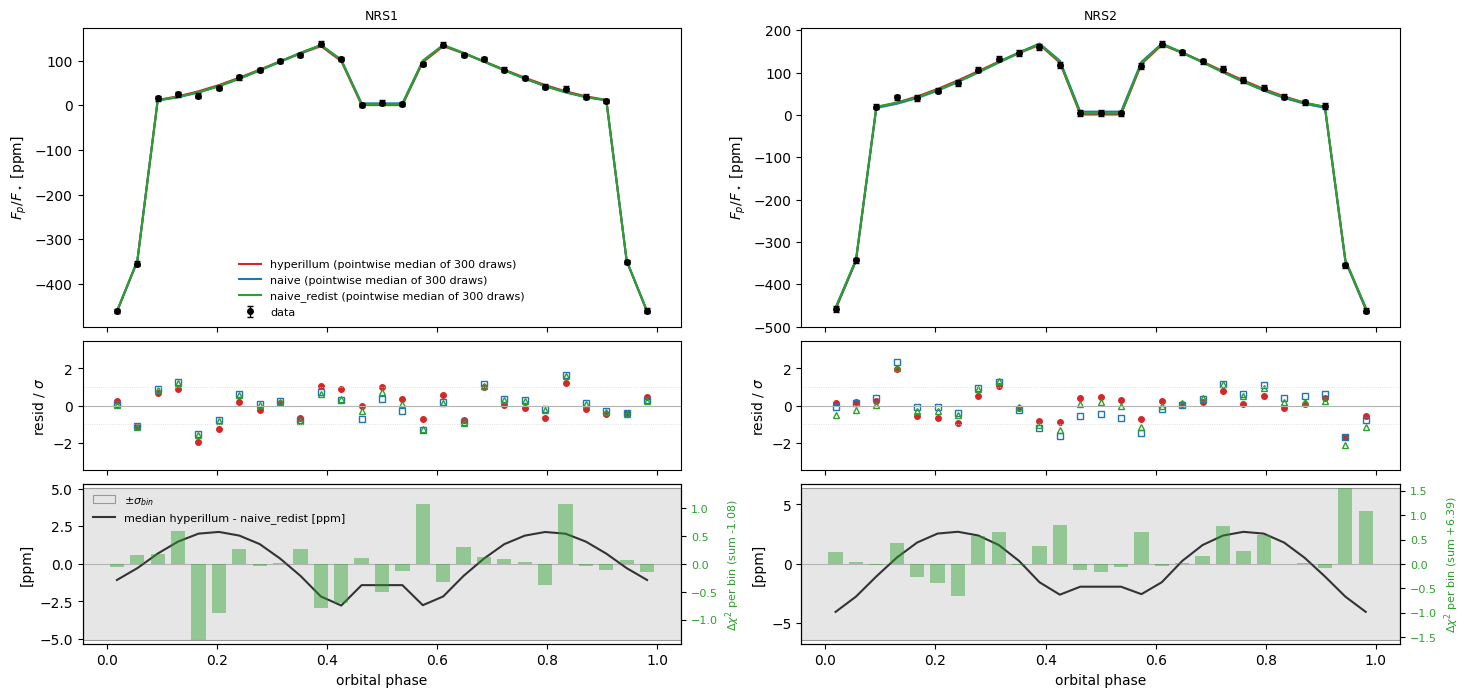

In [6]:
PAPER_MODE = False
N_DRAWS = 300   # forward models per insolation model

for den in [m for m in fits if m != INSOL_REF]:   # panel 3 is pairwise: one figure per alternative, each against the truth's own model
    plot_posterior_predictive(logls, fits, num=INSOL_REF, den=den, n=N_DRAWS, colors=COLOR, n_jobs=N_JOBS)
    paper_figure(f"dynesty_posterior_predictive_{den}_{PLANET}", PAPER_MODE, tight=False); plt.show() # per-bin Δχ², computed as [(y−best_a)² − (y−best_b)²]/σ², so a bar is positive where model b fits that bin better.


## 4. Bias analysis

The one-seed fits against the noiseless truth: what this dataset would make you report (the posterior medians) against the bias itself — the misspecified model fitted to the **noiseless** binned truth with the least-squares fits of the bias analysis (`simple_bias_analysis.fit_naive` for `naive`, the joint `fit_redist` in $(A_B, F)$ for `naive_redist`; offset free, no seed). For `naive_redist` the fitted $F$ is the false-positive redistribution the point-source model needs to mimic hyperillumination, and the nightside temperature it implies is printed. The bias is quoted in units of this seed's posterior width and of the Fisher $\sigma$ of the bias analysis; the two agree where the posterior is Gaussian and not truncated by the prior ($A_B \geq 0$, $F \geq 0$).

Lower panel: everything minus the binned truth, against $\pm\sigma_{\rm bin}$. Black points are the data, i.e. the noise the medians are chasing. The dotted grey line is the numerical floor — the *same* model at the *same* parameters, evaluated on the likelihood's coarser grid instead of the truth's. It should sit on zero; whatever it does is grid resolution, not physics, and the printed bias/floor ratio is the gate on every bias number of this figure.


NOISELESS fit(s) to the NOISELESS truth  (offset free, no noise, no seed - this is THE bias; the least-squares fits of the bias analysis, jointly over the detectors):
   naive        A_B 0.1582   bias -0.0418 = -1.59 sigma_A_B (posterior, this seed) = -1.57 sigma_Fisher   ->   dT_sub/T = +1.28 %
                |dA_B|/sigma_A_B = 1.59   (all detectors scaled alike: the bias is a 1.6 sigma effect at the delivered noise)
                bias / floor = 11.644 / 0.002 = 7048.0x   ->   bias resolved
   naive_redist A_B 0.1061   bias -0.0939 = -2.82 sigma_A_B (posterior, this seed) = -2.71 sigma_Fisher   ->   dT_sub/T = +2.27 %
                F   0.0141   false positive (truth F = 0) = 2.91 sigma_F (posterior), sigma_F,Fisher = 0.0048 (one-sided at F = 0: indicative only)   ->   implied nightside T = 803 K
                |dA_B|/sigma_A_B = 2.82   (all detectors scaled alike: the bias is a 2.8 sigma effect at the delivered noise)
                bias / floor = 5.458 / 0.002 = 3303.8x   ->  

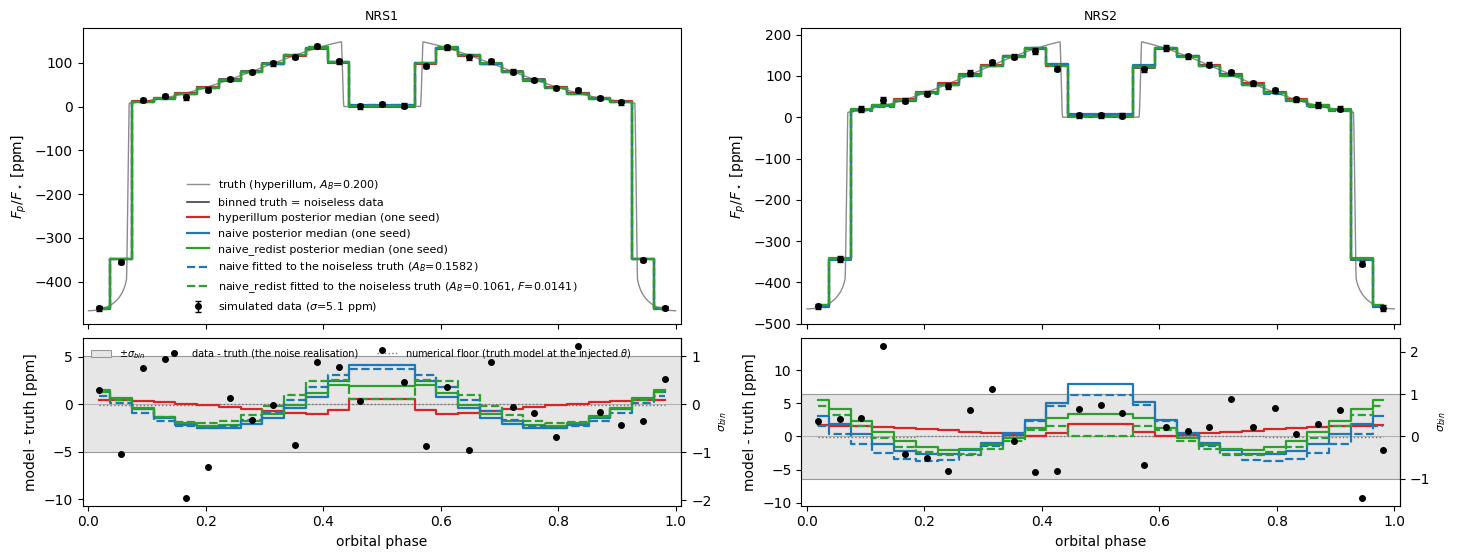

In [7]:
PAPER_MODE = False
fig, _, out = plot_noisy_vs_truth(cfg, data, logls, fits, A_B_true, base, insolation_truth=INSOL_TRUTH,
                                  colors=COLOR)   # the noiseless fits (the bias) in A_B_FIT_BOUNDS, as in the bias analysis; one column per detector for a joint fit
paper_figure(f"dynesty_noisy_vs_truth_{PLANET}", PAPER_MODE, fig=fig, tight=False)
plt.show()

## 5. Derived quantities

The posterior pushed through to physics, each model through **its own** temperature map - i.e. what you would infer if you believed that model: the substellar, terminator and antistellar (nightside) temperatures, the occultation depth and the dayside brightness temperature (per detector for a joint fit; the temperatures are band-independent).
`T_term` > 0 for naive is an interpolation artefact: it is `np.interp` of the temperature grid at exactly 90°, between the last dayside and the first nightside node. The naive and hyperillum nightsides (`T_anti`) are exactly 0 K (drawn as lines, not histograms); under `naive_redist` it is the redistributed nightside $T^4 \propto (1-A_B)\,F\,S/2$ — the nightside temperature an observer would infer from a model that is free to redistribute heat, against a truth with none.


NRS1  hyperillum   occultation_depth  151.27 ppm   phase-curve maximum  141.77 ppm
NRS1  naive        occultation_depth  148.77 ppm   phase-curve maximum  137.86 ppm


NRS1  naive_redist occultation_depth  148.77 ppm   phase-curve maximum  137.86 ppm


NRS2  hyperillum   occultation_depth  187.26 ppm   phase-curve maximum  176.48 ppm
NRS2  naive        occultation_depth  184.05 ppm   phase-curve maximum  171.05 ppm


NRS2  naive_redist occultation_depth  184.06 ppm   phase-curve maximum  171.06 ppm


hyperillum   NRS1  depth  156.1 +2.4 -2.8 ppm (thermal 149.7, reflected 6.3)   T_bright 2373.8 +17.2 -20.7 K
hyperillum   NRS2  depth  192.0 +2.5 -3.0 ppm (thermal 185.6, reflected 6.3)   T_bright 2369.1 +17.3 -20.7 K
                   T_sub 2695.6 K   T_term 1505.8 K   T_anti    0.0 K
naive        NRS1  depth  157.5 +2.7 -2.5 ppm (thermal 151.3, reflected 6.2)   T_bright 2385.2 +19.3 -18.1 K
naive        NRS2  depth  192.9 +2.8 -2.6 ppm (thermal 186.7, reflected 6.2)   T_bright 2376.7 +19.3 -18.1 K
                   T_sub 2715.7 K   T_term  548.3 K   T_anti    0.0 K
naive_redist NRS1  depth  159.9 +3.4 -3.0 ppm (thermal 153.7, reflected 6.2)   T_bright 2402.4 +24.6 -21.3 K
naive_redist NRS2  depth  195.6 +3.6 -3.1 ppm (thermal 189.4, reflected 6.2)   T_bright 2395.0 +24.2 -21.3 K
                   T_sub 2732.7 K   T_term  843.6 K   T_anti  739.2 K +89.8 -96.7 (< 865 K at 95 %)


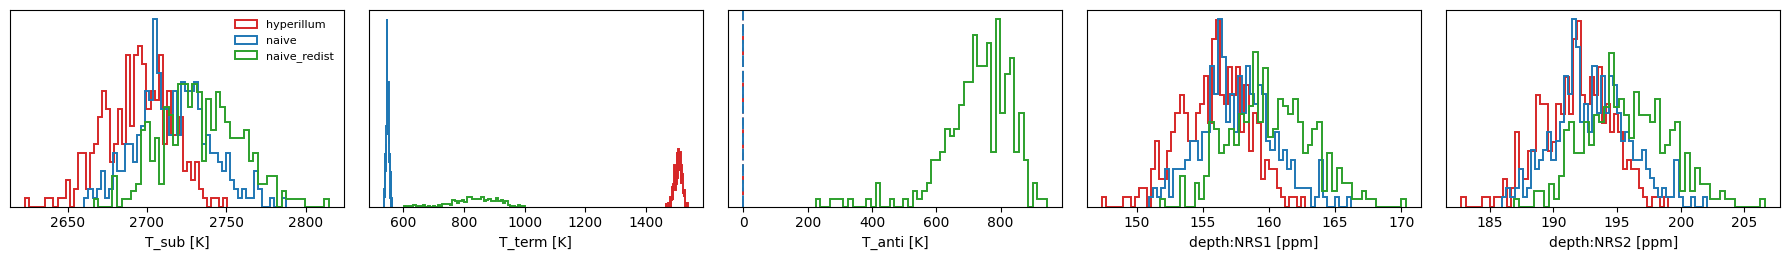

In [8]:
PAPER_MODE = False
# Check on the factored-out pcurve_params: for a thermal-only, transit-free config the occultation depth is close to the peak of the phase curve model_pcurve builds from the same sp.ModelParams
# (sub-percent: at these a/R* the visible maximum sits at ingress, not at full phase).
for c, lab in zip(cfgs, LABELS or [""]):
    cfg_th = replace(c, reflected=False, transit=False)
    for m in fits:
        F_ = base["F"] if "F" in PSETS[m].names else None   # only "naive_redist" has one, and at the injected truth it is 0
        _, y_ = model_pcurve(cfg_th, m, A_B_true, F=F_, n_t=200 * c.n_bins)
        d_ = occultation_depth(pcurve_params(cfg_th, m, A_B_true, F=F_), stellar_grid=c.stellar_grid, emissivity=cfg_th.emissivity)
        print(f"{lab:5s} {m:12s} occultation_depth {d_:7.2f} ppm   phase-curve maximum {y_.max():7.2f} ppm")

der = {m: derived_samples(logls[m], equal_samples(fits[m], N_DRAWS, seed=0), n_jobs=N_JOBS) for m in fits}
SUF = [f":{lab}" for lab in LABELS] if JOINT else [""]          # the per-detector depth keys of a joint fit ("depth:NRS1", ...)
for name, d in der.items():
    for c, lab, suf in zip(cfgs, LABELS or [""], SUF):
        q, q_th = np.percentile(d["depth" + suf], [16, 50, 84]), np.percentile(d["depth_th" + suf], [16, 50, 84])
        Tb = brightness_temperature(d["depth_th" + suf], c)
        print(f"{name:12s} {lab:5s} depth {q[1]:6.1f} +{q[2]-q[1]:.1f} -{q[1]-q[0]:.1f} ppm (thermal {q_th[1]:.1f}, reflected {np.median(d['depth_refl' + suf]):.1f})   T_bright {Tb[1]:6.1f} +{Tb[2]-Tb[1]:.1f} -{Tb[1]-Tb[0]:.1f} K")
    Ta = np.percentile(d["T_anti"], [16, 50, 84, 95])
    print(f"{'':12s} {'':5s} T_sub {np.median(d['T_sub']):6.1f} K   T_term {np.median(d['T_term']):6.1f} K   T_anti {Ta[1]:6.1f} K" + (f" +{Ta[2]-Ta[1]:.1f} -{Ta[1]-Ta[0]:.1f} (< {Ta[3]:.0f} K at 95 %)" if name in F_MODELS else ""))

KEYS = ("T_sub", "T_term", *(("T_anti",) if F_MODELS else ()), *("depth" + suf for suf in SUF))   # the nightside only becomes a distribution with a redistributing model; one depth panel per detector
plot_derived(der, keys=KEYS, colors=COLOR); paper_figure(f"dynesty_derived_{PLANET}", PAPER_MODE); plt.show()
